# Vulnerability data → model parameters

Queries three public sources and turns them into the inputs of the model in `ODEtoVuln_daily.ipynb`
([vulnapocalypse-modeling](https://github.com/jo5iah/vulnapocalypse-modeling), which includes this repository as
the submodule `vulnapocalypse-data`).

| Source | What it provides here |
|---|---|
| **NVD** (`services.nvd.nist.gov/rest/json/cves/2.0`) | the CVE corpus, publication rates and history, CVSS attack vectors, and the CISA KEV flags and dates mirrored into each record |
| **CISA KEV** (`known_exploited_vulnerabilities.json`) | which CVEs are known-exploited, when CISA added them, and the federal remediation deadline |
| **MITRE** (`cveawg.mitre.org/api/cve/…`) | per-CVE CNA record: reservation and publication timestamps, used to check disclosure timing |

Two populations are measured: **all software** (the global ecosystem) and **one CPE family**, Microsoft
SharePoint, as a stand-in for enterprise server software.

Every response is cached under `data/`, so re-running is free and the outputs are reproducible. NVD's
anonymous rate limit is 5 requests per 30 s; the fetcher waits 6.6 s between calls. An API key from
nvd.nist.gov goes faster.

**Snapshot 2026-11-16**, set by `AS_OF` in the next cell. The notebook writes:

- `data/derived_params.json`: the measured quantities the model reads (section 7);
- `data/global_history.json`: per-year publication rates (section 6);
- `data/trend_series_<snapshot>.json` and `data/trend_daily_<snapshot>.json`: the monthly and daily series
  (sections 6b and 6c), which drive the model's transient and the inflow figure;
- `data/sharepoint_union.json`: the de-duplicated CVE set for the CPE family (section 4).

Section 8 draws the one figure of the data page,
[jo5iah.github.io/vulnapocalypse-data](https://jo5iah.github.io/vulnapocalypse-data/). The page's text is in
`VulnData.md`; `python build_html.py VulnData index` combines it with that figure. As in the model notebook, the
written account lives in the document, not here.

In [1]:
import datetime as dt
import json
import statistics as st
import time
import urllib.parse
import urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)
NVD = "https://services.nvd.nist.gov/rest/json/cves/2.0"
CPE_API = "https://services.nvd.nist.gov/rest/json/cpes/2.0"
KEV_FEED = "https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json"
MITRE = "https://cveawg.mitre.org/api/cve/"
UA = {"User-Agent": "vulnapocalypse-research/1.0"}

AS_OF = dt.date(2026, 11, 16)     # the snapshot these numbers describe
TAG = AS_OF.isoformat()          # cache keys carry it, so snapshots never overwrite each other
NVD_GAP = 6.6                    # seconds between calls: 5 requests / 30 s anonymous limit
_last_call = [0.0]


def fetch(url, cache, retries=4):
    """GET with on-disk caching and rate limiting; cached responses cost nothing."""
    path = DATA / cache
    if path.exists():
        return json.loads(path.read_text())
    for attempt in range(retries):
        wait = NVD_GAP - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=180) as r:
                payload = json.loads(r.read())
            _last_call[0] = time.time()
            path.write_text(json.dumps(payload))
            return payload
        except Exception as exc:                                    # noqa: BLE001
            print(f"  retry {attempt + 1}/{retries} on {cache}: {type(exc).__name__} "
                  f"{getattr(exc, 'code', '')}")
            _last_call[0] = time.time()
            time.sleep(15)
    raise RuntimeError(f"could not fetch {cache}")


def nvd(cache, flags=(), **params):
    """NVD query; `flags` are valueless parameters such as hasKev."""
    url = NVD + "?" + urllib.parse.urlencode(params, safe=":")
    for flag in flags:
        url += f"&{flag}"
    return fetch(url, cache)


day = lambda stamp: dt.date.fromisoformat(stamp[:10])
print("helpers ready · cache:", DATA.resolve())

helpers ready · cache: /home/jo5iah/vulnapocalypse/data


## 1. The global corpus and its current publication rate

NVD caps any single publication-date range at 120 days, so a year of publications takes four windows. The
publication rate is the model's $\gamma + \sigma S$ — the two are additive in the equations and NVD cannot
distinguish "found in old code" from "shipped broken last month," so the measurement is their sum.

In [2]:
corpus_total = nvd(f"nvd_total_{TAG}.json", resultsPerPage=1)["totalResults"]

windows = []
for i in range(4):
    end = AS_OF - dt.timedelta(days=91 * i)
    start = end - dt.timedelta(days=91)
    n = nvd(f"nvd_window_{TAG}_{i}.json", resultsPerPage=1,
            pubStartDate=f"{start}T00:00:00.000", pubEndDate=f"{end}T23:59:59.999")["totalResults"]
    windows.append({"start": str(start), "end": str(end), "count": n})
    print(f"  {start} .. {end}   {n:>6,} CVEs   {n / 91:6.1f}/day")

year_count = sum(w["count"] for w in windows)
gamma_global = year_count / 364.0
gamma_global_recent = windows[0]["count"] / 91.0

print(f"\nNVD corpus: {corpus_total:,} CVEs")
print(f"last 364 days: {year_count:,} → {gamma_global:.0f}/day")
print(f"most recent 91 days: {windows[0]['count']:,} → {gamma_global_recent:.0f}/day "
      f"({gamma_global_recent / gamma_global:.1f}× the trailing year)")

  2026-08-17 .. 2026-11-16   47,676 CVEs    523.9/day


  2026-05-18 .. 2026-08-17   27,375 CVEs    300.8/day


  2026-02-16 .. 2026-05-18   18,536 CVEs    203.7/day


  2025-11-17 .. 2026-02-16   14,626 CVEs    160.7/day

NVD corpus: 426,069 CVEs
last 364 days: 108,213 → 297/day
most recent 91 days: 47,676 → 524/day (1.8× the trailing year)


## 2. Exploitation: the CISA KEV catalog

KEV is the only public, curated record of *observed* exploitation. Two properties matter for the model.

It is **cumulative** — entries are essentially never withdrawn — so the catalog size is total exploitation
influx over KEV's lifetime, *not* the model's $E$ (which has an outflow). What KEV gives directly is the
**influx rate** into $E$ and the **lag** between disclosure and observed exploitation.

It is also a **lower bound**: KEV requires reliable evidence of exploitation and relevance to federal
networks, so quiet or narrowly-targeted exploitation is missing. Every exploitation parameter derived
here inherits that downward bias.

In [3]:
kev_catalog = fetch(KEV_FEED, f"cisa_kev_{TAG}.json")
kev_nvd = nvd(f"nvd_kev_{TAG}.json", flags=("hasKev",), resultsPerPage=2000)["vulnerabilities"]

kev_by_year, lags, due_windows = {}, [], []
for v in kev_nvd:
    c = v["cve"]
    added, published = day(c["cisaExploitAdd"]), day(c["published"])
    kev_by_year[added.year] = kev_by_year.get(added.year, 0) + 1
    lags.append((added - published).days)
    if c.get("cisaActionDue"):
        due_windows.append((day(c["cisaActionDue"]) - added).days)

# 2022 to the snapshot. 2021 is KEV's launch year and its additions are a backfill of
# pre-existing exploitation, not a rate, so the series starts after it. Dividing total additions
# by elapsed days rather than averaging per-year rates lets the partial current year contribute
# at its true weight instead of as a full year.
INFLUX_FROM = dt.date(2022, 1, 1)
influx_days = (AS_OF - INFLUX_FROM).days
influx_adds = sum(n for y, n in kev_by_year.items() if y >= INFLUX_FROM.year)
kev_rate_global = influx_adds / influx_days
zero_day_share = sum(1 for l in lags if l <= 0) / len(lags)

print(f"KEV catalog: {kev_catalog['count']:,} entries (released {kev_catalog['dateReleased'][:10]})")
print(f"  = {len(kev_nvd) / corpus_total:.3%} of the NVD corpus")
print(f"additions per year: " + ", ".join(f"{y}:{kev_by_year[y]}" for y in sorted(kev_by_year)))
print(f"  {INFLUX_FROM.year}–{AS_OF} mean: {influx_adds:,} additions over {influx_days:,} "
      f"days = {kev_rate_global * 365:.0f}/yr = {kev_rate_global:.3f}/day  ← exploitation influx")
print(f"disclosure → KEV lag: median {st.median(lags):.0f} d, p10 {sorted(lags)[len(lags) // 10]} d, "
      f"p90 {sorted(lags)[9 * len(lags) // 10]:,} d")
print(f"  exploited on or before publication (zero-day path): {zero_day_share:.1%}")
print(f"CISA remediation deadline (due − added): median {st.median(due_windows):.0f} days")

KEV catalog: 1,781 entries (released 2026-11-13)
  = 0.418% of the NVD corpus
additions per year: 2021:311, 2022:555, 2023:187, 2024:186, 2025:245, 2026:297
  2022–2026-11-16 mean: 1,470 additions over 1,780 days = 301/yr = 0.826/day  ← exploitation influx
disclosure → KEV lag: median 216 d, p10 0 d, p90 2,577 d
  exploited on or before publication (zero-day path): 13.4%
CISA remediation deadline (due − added): median 21 days


## 3. Reachability, from CVSS attack vector

The model's $\varepsilon$ is the fraction of vulnerabilities that are actually reachable by an attacker.
The closest public proxy is the CVSS attack vector: NETWORK or ADJACENT_NETWORK means remotely reachable
given a deployed, exposed instance. This *overstates* $\varepsilon$ for a hardened estate and understates
it for an internet-facing one, so treat it as an upper anchor for a given population.

In [4]:
def network_share(vulns):
    """Fraction of CVEs whose CVSS attack vector is network-reachable, and the sample size."""
    scored = reachable = 0
    for v in vulns:
        metrics = v["cve"].get("metrics", {})
        for key in ("cvssMetricV40", "cvssMetricV31", "cvssMetricV30", "cvssMetricV2"):
            if key in metrics:
                data = metrics[key][0]["cvssData"]
                vector = (data.get("attackVector") or data.get("accessVector") or "").upper()
                scored += 1
                reachable += vector in ("NETWORK", "ADJACENT_NETWORK")
                break
    return (reachable / scored if scored else float("nan")), scored


eps_kev, n_kev = network_share(kev_nvd)
print(f"KEV population: {eps_kev:.1%} network-reachable (n={n_kev:,})")

KEV population: 75.6% network-reachable (n=1,781)


## 4. One CPE family: Microsoft SharePoint

SharePoint has no single CPE — NVD spreads it across `sharepoint_server`, `sharepoint_foundation`,
`sharepoint_enterprise_server` and older names, and a CVE typically lists several. The CPE dictionary is
queried first to discover the product names, then each is swept and the results de-duplicated by CVE ID.

In [5]:
cpe_hits = fetch(CPE_API + "?keywordSearch=sharepoint&resultsPerPage=2000", "cpe_sharepoint.json")
products = sorted({c["cpe"]["cpeName"].split(":")[4] for c in cpe_hits["products"]
                   if c["cpe"]["cpeName"].split(":")[3] == "microsoft"})
print("SharePoint product names in the CPE dictionary:")
print("  " + ", ".join(products))

TARGETS = ["sharepoint_server", "sharepoint_foundation", "sharepoint_enterprise_server",
           "sharepoint_services", "sharepoint_portal_server", "sharepoint_team_services",
           "office_sharepoint_server", "sharepoint_designer"]

sharepoint = {}
for product in TARGETS:
    hits = nvd(f"nvd_sp_{product}_{TAG}.json", resultsPerPage=2000,
               virtualMatchString=f"cpe:2.3:a:microsoft:{product}")
    for v in hits["vulnerabilities"]:
        sharepoint[v["cve"]["id"]] = v
    print(f"  {product:<30} {hits['totalResults']:>4} CVEs   union {len(sharepoint):>4}")

# the de-duplicated union is an output, not scratch: the model notebook reads it
Path("data/sharepoint_union.json").write_text(json.dumps({"as_of": str(AS_OF),
                                                         "vulnerabilities": list(sharepoint.values())}))
sp = list(sharepoint.values())
pubs = sorted(day(v["cve"]["published"]) for v in sp)
sp_365 = sum(1 for d in pubs if (AS_OF - d).days <= 365)
sp_1095 = sum(1 for d in pubs if (AS_OF - d).days <= 1095)
gamma_sp, gamma_sp_recent = sp_1095 / 1095.0, sp_365 / 365.0

sp_kev = [v for v in sp if v["cve"].get("cisaExploitAdd")]
sp_lags = [(day(v["cve"]["cisaExploitAdd"]) - day(v["cve"]["published"])).days for v in sp_kev]
kev_rate_sp = len(sp_kev) / ((AS_OF - day(min(v["cve"]["cisaExploitAdd"] for v in sp_kev))).days)
eps_sp, n_sp = network_share(sp)

per_year = {}
for d in pubs:
    per_year[d.year] = per_year.get(d.year, 0) + 1

print(f"\n{len(sp)} SharePoint CVEs, {pubs[0]} → {pubs[-1]}")
print("  per year: " + ", ".join(f"{y}:{per_year[y]}" for y in sorted(per_year) if y >= 2018))
print(f"  3-year rate {gamma_sp:.3f}/day · last-365 rate {gamma_sp_recent:.3f}/day "
      f"({gamma_sp_recent / gamma_sp:.1f}× — a live surge, not a baseline)")
print(f"  in KEV: {len(sp_kev)}/{len(sp)} = {len(sp_kev) / len(sp):.2%}  "
      f"({(len(sp_kev) / len(sp)) / (len(kev_nvd) / corpus_total):.1f}× the global exploitation rate)")
print(f"  exploitation influx {kev_rate_sp:.4f}/day · disclosure → KEV median {st.median(sp_lags):.0f} d · "
      f"{sum(1 for l in sp_lags if l <= 0)}/{len(sp_lags)} exploited by publication day")
print(f"  network-reachable: {eps_sp:.1%} (n={n_sp})")

SharePoint product names in the CPE dictionary:
  office_sharepoint_server, sharepoint_designer, sharepoint_enterprise_server, sharepoint_foundation, sharepoint_online, sharepoint_portal_server, sharepoint_server, sharepoint_server_client_components_sdk, sharepoint_services, sharepoint_team_services, word_automation_services


  sharepoint_server               642 CVEs   union  642


  sharepoint_foundation           226 CVEs   union  671


  sharepoint_enterprise_server    256 CVEs   union  718


  sharepoint_services              19 CVEs   union  720


  sharepoint_portal_server          6 CVEs   union  722


  sharepoint_team_services          4 CVEs   union  725


  office_sharepoint_server         18 CVEs   union  741


  sharepoint_designer              11 CVEs   union  747

747 SharePoint CVEs, 2003-12-15 → 2026-10-15
  per year: 2018:55, 2019:48, 2020:121, 2021:53, 2022:29, 2023:27, 2024:24, 2025:45, 2026:177
  3-year rate 0.225/day · last-365 rate 0.499/day (2.2× — a live surge, not a baseline)
  in KEV: 22/747 = 2.95%  (7.0× the global exploitation rate)
  exploitation influx 0.0120/day · disclosure → KEV median 84 d · 3/22 exploited by publication day
  network-reachable: 78.6% (n=747)


## 5b. Publication-date rates are undercounts

A window's count is not fixed when the window closes. NVD keeps ingesting records whose publication date falls
inside a window for weeks afterwards, so any rate measured close to the present is low. The size of the effect
is measurable: re-query a window that was already closed when it was first counted.

In [6]:
RECHECK = ("2026-05-07", "2026-08-06", 25_148)      # window, and the count it returned on 2026-08-06
start, end, first_count = RECHECK
later = nvd(f"nvd_window_recheck_{start}_{end[5:]}.json", resultsPerPage=1,
            pubStartDate=f"{start}T00:00:00.000", pubEndDate=f"{end}T23:59:59.999")["totalResults"]
LATE_ARRIVAL = later / first_count - 1
print(f"window {start} .. {end}")
print(f"  counted on {end}: {first_count:,}")
print(f"  counted on {AS_OF}: {later:,}   ({later - first_count:+,} = {LATE_ARRIVAL:+.2%} in "
      f"{(AS_OF - dt.date.fromisoformat(end)).days} days)")
print(f"  -> every gamma derived from publication windows is low by at least this margin, and by more")
print(f"     for the most recent weeks. The direction is always the same: measured rates understate.")

# the corpus grows faster than the windowed rate implies, for the same reason
corpus_growth = (corpus_total - 373_818) / (AS_OF - dt.date(2026, 8, 6)).days
print(f"\ncorpus grew {corpus_total - 373_818:+,} in "
      f"{(AS_OF - dt.date(2026, 8, 6)).days} days = {corpus_growth:.0f}/day, against a windowed "
      f"publication rate of {gamma_global_recent:.0f}/day")
print(f"  the gap is late arrivals plus records published before the last snapshot")

window 2026-05-07 .. 2026-08-06
  counted on 2026-08-06: 25,148
  counted on 2026-11-16: 25,361   (+213 = +0.85% in 102 days)
  -> every gamma derived from publication windows is low by at least this margin, and by more
     for the most recent weeks. The direction is always the same: measured rates understate.

corpus grew +52,251 in 102 days = 512/day, against a windowed publication rate of 524/day
  the gap is late arrivals plus records published before the last snapshot


## 5. MITRE cross-check on disclosure timing

NVD's `published` is when *NVD* published the record, which can trail the CNA. For the SharePoint CVEs that
reached KEV, MITRE's CVE record gives the CNA's own `datePublished` — worth checking before treating
publication-to-KEV lag as a disclosure-to-exploitation interval.

In [7]:
checks = []
for v in sorted(sp_kev, key=lambda v: v["cve"]["cisaExploitAdd"], reverse=True)[:6]:
    cve_id = v["cve"]["id"]
    try:
        rec = fetch(MITRE + cve_id, f"mitre_{cve_id}.json")
    except RuntimeError:
        continue
    meta = rec.get("cveMetadata", {})
    if meta.get("datePublished"):
        gap = (day(v["cve"]["published"]) - day(meta["datePublished"])).days
        checks.append(gap)
        print(f"  {cve_id}  CNA {meta['datePublished'][:10]}  NVD {v['cve']['published'][:10]}  "
              f"Δ {gap:+d} d  KEV {v['cve']['cisaExploitAdd'][:10]}  ({meta.get('assignerShortName', '')})")

if checks:
    print(f"\nNVD lags the CNA by a median of {st.median(checks):.0f} days on this sample — "
          f"small next to the KEV lags above, so NVD dates are used throughout.")

  CVE-2026-65660  CNA 2026-08-11  NVD 2026-08-11  Δ +0 d  KEV 2026-09-25  (microsoft)
  CVE-2026-55040  CNA 2026-07-14  NVD 2026-07-14  Δ +0 d  KEV 2026-08-18  (microsoft)
  CVE-2026-50522  CNA 2026-07-14  NVD 2026-07-14  Δ +0 d  KEV 2026-07-22  (microsoft)
  CVE-2026-58644  CNA 2026-07-14  NVD 2026-07-14  Δ +0 d  KEV 2026-07-16  (microsoft)
  CVE-2026-56164  CNA 2026-07-14  NVD 2026-07-14  Δ +0 d  KEV 2026-07-14  (microsoft)
  CVE-2026-45659  CNA 2026-05-22  NVD 2026-05-22  Δ +0 d  KEV 2026-07-01  (microsoft)

NVD lags the CNA by a median of 0 days on this sample — small next to the KEV lags above, so NVD dates are used throughout.


## 6. Publication history, 2008 to the snapshot

The per-year publication rate drives the transient runs in the model notebook: the equilibria it computes are
targets, and locating the present state requires knowing what the inflow has actually been. NVD caps a
publication-date range at 120 days, so each year is swept in 110-day windows. Cache keys encode the date range
rather than a year index, because the final window of the current year re-splits as the snapshot advances.

Note that the counts are as-measured. Section 5b shows that a closed window keeps growing, so early years are
complete while the most recent are undercounts; the series is not back-corrected.

In [8]:
HISTORY_FROM = 2008
WINDOW_DAYS = 110

history = {}
for year in range(HISTORY_FROM, AS_OF.year + 1):
    start = dt.date(year, 1, 1)
    year_end = min(dt.date(year, 12, 31), AS_OF)
    windows, total = [], 0
    while start <= year_end:
        stop = min(start + dt.timedelta(days=WINDOW_DAYS), year_end)
        n = nvd(f"hist_{start}_{stop}.json", resultsPerPage=1,
                pubStartDate=f"{start}T00:00:00.000", pubEndDate=f"{stop}T23:59:59.999")["totalResults"]
        windows.append([str(start), str(stop), n])
        total += n
        start = stop + dt.timedelta(days=1)
    days = (year_end - dt.date(year, 1, 1)).days + 1
    history[year] = {"total": total, "windows": windows, "days": days}
    print(f"  {year}: {total:>7,} over {days:>3} days = {total / days:>6.1f}/day"
          + ("   (partial year)" if year == AS_OF.year else ""))

Path("data/global_history.json").write_text(json.dumps(history, indent=1))
rate = {y: history[y]["total"] / history[y]["days"] for y in history}
first, last = min(rate), max(rate)
span = last - first
print(f"\nwrote data/global_history.json — {first}–{last}")
print(f"  {rate[first] * 365.25:,.0f}/yr → {rate[last] * 365.25:,.0f}/yr annualized, "
      f"CAGR {(rate[last] / rate[first]) ** (1 / span) - 1:+.1%} over {span} years")
cum = 0
second_diff = []
totals = [history[y]["total"] for y in sorted(history)]
for i in range(2, len(totals)):
    second_diff.append(sum(totals[:i + 1]) - 2 * sum(totals[:i]) + sum(totals[:i - 1]))
print(f"  cumulative {sum(totals):,}; second differences positive in "
      f"{sum(1 for d in second_diff if d > 0)} of {len(second_diff)} years "
      f"(deceleration would be required for the latent pool to be depleting)")

  2008:   5,664 over 366 days =   15.5/day
  2009:   5,778 over 365 days =   15.8/day
  2010:   4,667 over 365 days =   12.8/day
  2011:   4,172 over 365 days =   11.4/day
  2012:   5,351 over 366 days =   14.6/day
  2013:   5,324 over 365 days =   14.6/day
  2014:   8,008 over 365 days =   21.9/day
  2015:   6,595 over 365 days =   18.1/day
  2016:   6,517 over 366 days =   17.8/day
  2017:  18,113 over 365 days =   49.6/day
  2018:  18,154 over 365 days =   49.7/day
  2019:  18,938 over 365 days =   51.9/day
  2020:  19,222 over 366 days =   52.5/day
  2021:  21,950 over 365 days =   60.1/day
  2022:  26,431 over 365 days =   72.4/day
  2023:  30,949 over 365 days =   84.8/day
  2024:  40,704 over 366 days =  111.2/day
  2025:  49,972 over 365 days =  136.9/day


  2026: 100,792 over 320 days =  315.0/day   (partial year)

wrote data/global_history.json — 2008–2026
  5,652/yr → 115,045/yr annualized, CAGR +18.2% over 18 years
  cumulative 397,301; second differences positive in 12 of 17 years (deceleration would be required for the latent pool to be depleting)


## 6b. Monthly series, for the shape of the trend

Section 6 answers "what has the inflow been", which is all the transient runs need. Asking instead *how the
inflow is changing* — whether growth is accelerating, and whether that acceleration is itself turning — needs
derivatives, and derivatives need even spacing. The 110-day windows restart at each year boundary, so every
year ends in a stub window of 1 to 35 days; the rates are right but the sampling grid is not usable for
differencing.

This section re-sweeps the same range one calendar month at a time and pairs it with KEV additions per month,
which come free from the catalog's own `dateAdded`. Cache keys are date ranges, so a closed month is fetched
once and never again. Two things travel with the output and are recorded in it rather than corrected for:

- the last month is **partial**, ending at the snapshot, and is flagged as such;
- by section 5b a closed window keeps growing for about a fortnight, so the final one or two months are
  undercounts. Any derivative taken at the right-hand end inherits that, and the bias has a known sign.

In [9]:
MONTHLY_FROM = dt.date(2008, 1, 1)


def month_starts(first, last):
    y, m = first.year, first.month
    while dt.date(y, m, 1) <= last:
        yield dt.date(y, m, 1)
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)


monthly, t0 = [], time.time()
for start in month_starts(MONTHLY_FROM, AS_OF):
    nxt = (dt.date(start.year + 1, 1, 1) if start.month == 12
           else dt.date(start.year, start.month + 1, 1))
    stop, full = min(nxt - dt.timedelta(days=1), AS_OF), nxt - dt.timedelta(days=1) <= AS_OF
    n = nvd(f"hist_m_{start}_{stop}.json", resultsPerPage=1,
            pubStartDate=f"{start}T00:00:00.000", pubEndDate=f"{stop}T23:59:59.999")["totalResults"]
    monthly.append({"month": f"{start:%Y-%m}", "start": str(start), "stop": str(stop),
                    "days": (stop - start).days + 1, "cves": n, "complete": bool(full)})
print(f"  {len(monthly)} months fetched in {time.time() - t0:.0f} s "
      f"(last is partial: {monthly[-1]['month']}, {monthly[-1]['days']} days)")

# KEV additions on the same grid, from the catalog's own dateAdded
kev_monthly = {}
for v in kev_nvd:
    a = day(v["cve"]["cisaExploitAdd"])
    kev_monthly[f"{a:%Y-%m}"] = kev_monthly.get(f"{a:%Y-%m}", 0) + 1
kev_series = [{"month": m["month"], "days": m["days"],
               "kev": kev_monthly.get(m["month"], 0), "complete": m["complete"]}
              for m in monthly]

# the monthly sweep must reproduce section 6's yearly totals, up to late arrivals between the
# two fetches; a large gap would mean the windows do not tile the year
print("  year  monthly sum   section 6   delta")
for year in sorted({int(m["month"][:4]) for m in monthly}):
    ms = sum(m["cves"] for m in monthly if m["month"].startswith(str(year)))
    yr = history[year]["total"]
    flag = "" if abs(ms - yr) <= max(5, 0.005 * yr) else "   <-- check"
    print(f"  {year}  {ms:>11,}  {yr:>10,}  {ms - yr:>+6,}{flag}")

Path(f"data/trend_series_{TAG}.json").write_text(json.dumps(
    {"as_of": str(AS_OF), "note": "last month partial; final months undercount (see 5b)",
     "late_arrival_1wk": LATE_ARRIVAL, "monthly_cves": monthly,
     "monthly_kev_added": kev_series}, indent=1))
print(f"\nwrote data/trend_series_{TAG}.json — "
      f"{monthly[0]['month']} to {monthly[-1]['month']}, "
      f"{sum(m['cves'] for m in monthly):,} CVEs and "
      f"{sum(k['kev'] for k in kev_series):,} KEV additions")

  227 months fetched in 15 s (last is partial: 2026-11, 16 days)
  year  monthly sum   section 6   delta
  2008        5,664       5,664      +0
  2009        5,778       5,778      +0
  2010        4,667       4,667      +0
  2011        4,172       4,172      +0
  2012        5,351       5,351      +0
  2013        5,324       5,324      +0
  2014        8,008       8,008      +0
  2015        6,595       6,595      +0
  2016        6,517       6,517      +0
  2017       18,113      18,113      +0
  2018       18,154      18,154      +0
  2019       18,938      18,938      +0
  2020       19,222      19,222      +0
  2021       21,950      21,950      +0
  2022       26,431      26,431      +0
  2023       30,949      30,949      +0
  2024       40,704      40,704      +0
  2025       49,972      49,972      +0
  2026      100,792     100,792      +0

wrote data/trend_series_2026-11-16.json — 2008-01 to 2026-11, 397,301 CVEs and 1,781 KEV additions


## 6c. Daily series for the recent window

The monthly grid cannot describe the present. A filter wide enough to resolve a turning point
in a nineteen-year series extrapolates across its own half-window at each end, and for the
publication series that half-window is two years — the two years over which the rate went from
about 110/day to about 400/day. Any statement about the current regime taken off that grid is
the filter's opinion, not a measurement.

So this section re-sweeps the last `DAILY_DAYS` days one day at a time. It is the opposite
trade: no view of history, but the recent regime measured rather than extrapolated. Two
properties of the daily grid to carry forward:

- **Publication is strongly weekly.** CVEs are published on working days, and CISA adds to KEV
  in batches. Any smoother applied to either series has to span a whole number of weeks or the
  day-of-week cycle leaks straight into the derivatives.
- **The last fortnight is still filling.** Section 5b's late-arrival effect is a property of
  recent days specifically, so the right-hand end of the daily series is the most undercounted
  part of any series in this notebook.

In [10]:
DAILY_DAYS = 120                 # enough for a 90-day view plus a smoother's half-window

daily, t0 = [], time.time()
for k in range(DAILY_DAYS, -1, -1):
    d0 = AS_OF - dt.timedelta(days=k)
    n = nvd(f"hist_d_{d0}.json", resultsPerPage=1,
            pubStartDate=f"{d0}T00:00:00.000", pubEndDate=f"{d0}T23:59:59.999")["totalResults"]
    daily.append({"date": str(d0), "dow": d0.strftime("%a"), "cves": n})
print(f"  {len(daily)} days fetched in {time.time() - t0:.0f} s "
      f"({daily[0]['date']} to {daily[-1]['date']})")

kev_daily = {}
for v in kev_nvd:
    kev_daily[str(day(v["cve"]["cisaExploitAdd"]))] = \
        kev_daily.get(str(day(v["cve"]["cisaExploitAdd"])), 0) + 1
for row in daily:
    row["kev"] = kev_daily.get(row["date"], 0)

# the weekly cycle is the reason a daily smoother must span whole weeks; quantify it here
# rather than assert it, and do it on whole weeks so the mean is not itself day-biased
whole = daily[len(daily) % 7:]
by_dow = {}
for row in whole:
    by_dow.setdefault(row["dow"], []).append(row["cves"])
mean_all = sum(r["cves"] for r in whole) / len(whole)
print(f"  day-of-week means over {len(whole) // 7} whole weeks (overall {mean_all:,.0f}/day):")
for d0 in ("Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"):
    v = sum(by_dow[d0]) / len(by_dow[d0])
    print(f"    {d0}  {v:>7,.0f}   {v / mean_all:>5.2f}x")

recent = [r["cves"] for r in daily[-90:]]
recent_kev = [r["kev"] for r in daily[-90:]]
print(f"\n  last 90 days: {sum(recent):,} CVEs = {sum(recent) / 90:,.1f}/day, "
      f"{sum(recent_kev)} KEV additions = {sum(recent_kev) / 90:.3f}/day")
print(f"  against the trailing year: {gamma_global:,.1f}/day CVEs, "
      f"{kev_rate_global:.3f}/day KEV")

Path(f"data/trend_daily_{TAG}.json").write_text(json.dumps(
    {"as_of": str(AS_OF), "days": DAILY_DAYS,
     "note": "publication is weekly-cyclical; the final fortnight is still filling (see 5b)",
     "daily": daily}, indent=1))
print(f"\nwrote data/trend_daily_{TAG}.json")

  121 days fetched in 284 s (2026-07-19 to 2026-11-16)
  day-of-week means over 17 whole weeks (overall 489/day):
    Mon      451    0.92x
    Tue    1,086    2.22x
    Wed      533    1.09x
    Thu      534    1.09x
    Fri      463    0.95x
    Sat      216    0.44x
    Sun      140    0.29x

  last 90 days: 45,909 CVEs = 510.1/day, 111 KEV additions = 1.233/day
  against the trailing year: 297.3/day CVEs, 0.826/day KEV

wrote data/trend_daily_2026-11-16.json


## 7. From measurements to parameters

This cell writes `data/derived_params.json`. The model reads its `measured` block: corpus size, publication
rates over the trailing year and quarter, KEV entries and influx, the disclosure → KEV lag, the share
exploited by publication day, and the SharePoint counterparts. It also reads SharePoint's pre-disclosure
share from `params`.

The model does **not** take its rates from this cell. It calibrates the hazards and the throughput ceiling
$C$ itself, so that its conversion, integrated along the measured monthly history, reproduces the KEV
additions since 2023-01-01 (the data page, *Biases in the source data*). Its assumed rates ($\mu$, $\phi$,
$\lambda$, $\rho$, $\delta$, $\delta_d$) and the measured $\tau$ = 43 days are set in the model notebook's
first cell, and listed with their basis in the data page's parameter table.

The `params` sets below are an earlier, first-pass calibration (exploitation coefficients $\alpha$, a
targeting factor $\kappa$ and a ceiling $K$, solved from KEV influx against an equilibrium backlog). The
model no longer uses them, apart from SharePoint's `_zero_day_share`. They are kept so every archived
`derived_params_<snapshot>.json` keeps one schema. Their printed backlog comparison is a rough version of the
data page's backlog check, which the model performs properly.

In [11]:
MU = 1 / 30.0                    # a CVE is "new" for about one patch cycle
KAPPA_GLOBAL, KAPPA_SP = 0.50, 0.90
PHI_GLOBAL, PHI_SP = 1 / 1825.0, 1 / 3650.0      # 5-year / 10-year effective support horizon
TAU_DAYS, RHO, DELTA = 14.0, 0.20, 0.003         # patch start, adoption, runtime mitigation
LAM_GLOBAL, LAM_SP = 1 / 2000.0, 1 / 3650.0      # decommissioning
K_GLOBAL, K_SP = 1000.0, 25.0                    # simultaneous-exploitation ceiling


def build(name, gamma, kev_influx, zero_day_frac, eps, kappa, phi, lam, K, backlog_obs, corpus_note):
    """Solve for the exploitation coefficients that reproduce the observed KEV influx."""
    v_new = gamma / MU                              # fresh pool = one cycle of discovery
    v_exist = gamma / phi                           # backlog = inflow x residence time
    influx_exist = kev_influx * (1 - zero_day_frac)
    influx_new = kev_influx * zero_day_frac
    alpha_e = influx_exist / (v_exist * eps * kappa)
    alpha_n = influx_new / (v_new * eps * kappa)
    R = DELTA + RHO / (1 + TAU_DAYS) + lam
    return {
        "name": name, "gamma": gamma, "sigma_S": 0.0, "mu": MU, "phi": phi,
        "alpha_e": alpha_e, "alpha_n": alpha_n, "eps_e": eps, "eps_n": eps, "kappa": kappa,
        "delta": DELTA, "rho": RHO, "tau": TAU_DAYS, "lam": lam, "K": K,
        "_predicted_V_new": v_new, "_predicted_V_exist": v_exist, "_observed_backlog": backlog_obs,
        "_backlog_error": v_exist / backlog_obs - 1.0, "_kev_influx_per_day": kev_influx,
        "_zero_day_share": zero_day_frac, "_R": R, "_mean_days_exploited": 1 / R,
        "_predicted_E": kev_influx / R, "_corpus_note": corpus_note,
    }


PARAM_SETS = {
    "global": build("global software ecosystem", gamma_global, kev_rate_global, zero_day_share,
                    eps_kev, KAPPA_GLOBAL, PHI_GLOBAL, LAM_GLOBAL, K_GLOBAL, corpus_total,
                    f"NVD corpus {corpus_total:,} CVEs on {AS_OF}"),
    "sharepoint": build("Microsoft SharePoint", gamma_sp, kev_rate_sp,
                        sum(1 for l in sp_lags if l <= 0) / len(sp_lags), eps_sp, KAPPA_SP,
                        PHI_SP, LAM_SP, K_SP, len(sp), f"{len(sp)} SharePoint CVEs on {AS_OF}"),
}

for key, ps in PARAM_SETS.items():
    print(f"--- {key}: {ps['name']}")
    print(f"    gamma {ps['gamma']:.3f}/day   mu {ps['mu']:.4f}   phi {ps['phi']:.2e}   "
          f"kappa {ps['kappa']:.2f}   eps {ps['eps_e']:.3f}")
    print(f"    alpha_e {ps['alpha_e']:.3e}/day   alpha_n {ps['alpha_n']:.3e}/day   "
          f"ratio {ps['alpha_n'] / ps['alpha_e']:.0f}x")
    print(f"    R {ps['_R']:.4f}/day → {ps['_mean_days_exploited']:.0f} days in the exploited state")
    print(f"    backlog: predicted {ps['_predicted_V_exist']:,.0f} vs observed "
          f"{ps['_observed_backlog']:,} ({ps['_backlog_error']:+.1%})")
    print(f"    E* ≈ {ps['_predicted_E']:.2f} simultaneously exploited "
          f"({ps['_predicted_E'] / ps['K']:.1%} of K = {ps['K']:,.0f})")

out = {"as_of": str(AS_OF), "sources": {"nvd": NVD, "kev": KEV_FEED, "mitre": MITRE},
       "late_arrival_1wk": LATE_ARRIVAL,
       "measured": {"corpus_total": corpus_total, "cve_per_day_364": gamma_global,
                    "cve_per_day_91": gamma_global_recent, "kev_entries": len(kev_nvd),
                    "kev_share_of_corpus": len(kev_nvd) / corpus_total,
                    "kev_influx_per_day": kev_rate_global, "kev_lag_median_days": st.median(lags),
                    "kev_zero_day_share": zero_day_share,
                    "cisa_deadline_median_days": st.median(due_windows),
                    "network_share_kev": eps_kev, "sharepoint_cves": len(sp),
                    "sharepoint_kev": len(sp_kev), "sharepoint_per_day_1095": gamma_sp,
                    "sharepoint_per_day_365": gamma_sp_recent,
                    "sharepoint_kev_lag_median_days": st.median(sp_lags),
                    "network_share_sharepoint": eps_sp},
       "params": PARAM_SETS}
# both: the tagged archive, so a re-run cannot destroy the previous snapshot's parameters,
# and the untagged copy the model notebook reads as "current"
blob = json.dumps(out, indent=1)
Path(f"data/derived_params_{TAG}.json").write_text(blob)
Path("data/derived_params.json").write_text(blob)
print(f"\nwrote data/derived_params_{TAG}.json and data/derived_params.json")

--- global: global software ecosystem
    gamma 297.288/day   mu 0.0333   phi 5.48e-04   kappa 0.50   eps 0.756
    alpha_e 3.485e-06/day   alpha_n 3.286e-05/day   ratio 9x
    R 0.0168/day → 59 days in the exploited state
    backlog: predicted 542,551 vs observed 426,069 (+27.3%)
    E* ≈ 49.06 simultaneously exploited (4.9% of K = 1,000)
--- sharepoint: Microsoft SharePoint
    gamma 0.225/day   mu 0.0333   phi 2.74e-04   kappa 0.90   eps 0.786
    alpha_e 1.782e-05/day   alpha_n 3.422e-04/day   ratio 19x
    R 0.0166/day → 60 days in the exploited state
    backlog: predicted 820 vs observed 747 (+9.8%)
    E* ≈ 0.72 simultaneously exploited (2.9% of K = 25)

wrote data/derived_params_2026-11-16.json and data/derived_params.json


## 8. The shape of the inflow

The figure of the data page, inlined into `VulnData.md` at the `figure:inflow_derivatives` marker. It reads
the monthly and daily series written by sections 6b and 6c. The plotting style matches the model notebook's
figures. The data page discusses what the figure shows.

In [12]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

%config InlineBackend.figure_formats = ['retina']

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
ORD_BLUE = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK,
    "axes.labelcolor": SECONDARY, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": SECONDARY, "ytick.labelcolor": SECONDARY,
    "axes.edgecolor": BASELINE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlepad": 8, "lines.linewidth": 2.0, "legend.frameon": False, "figure.dpi": 120,
})

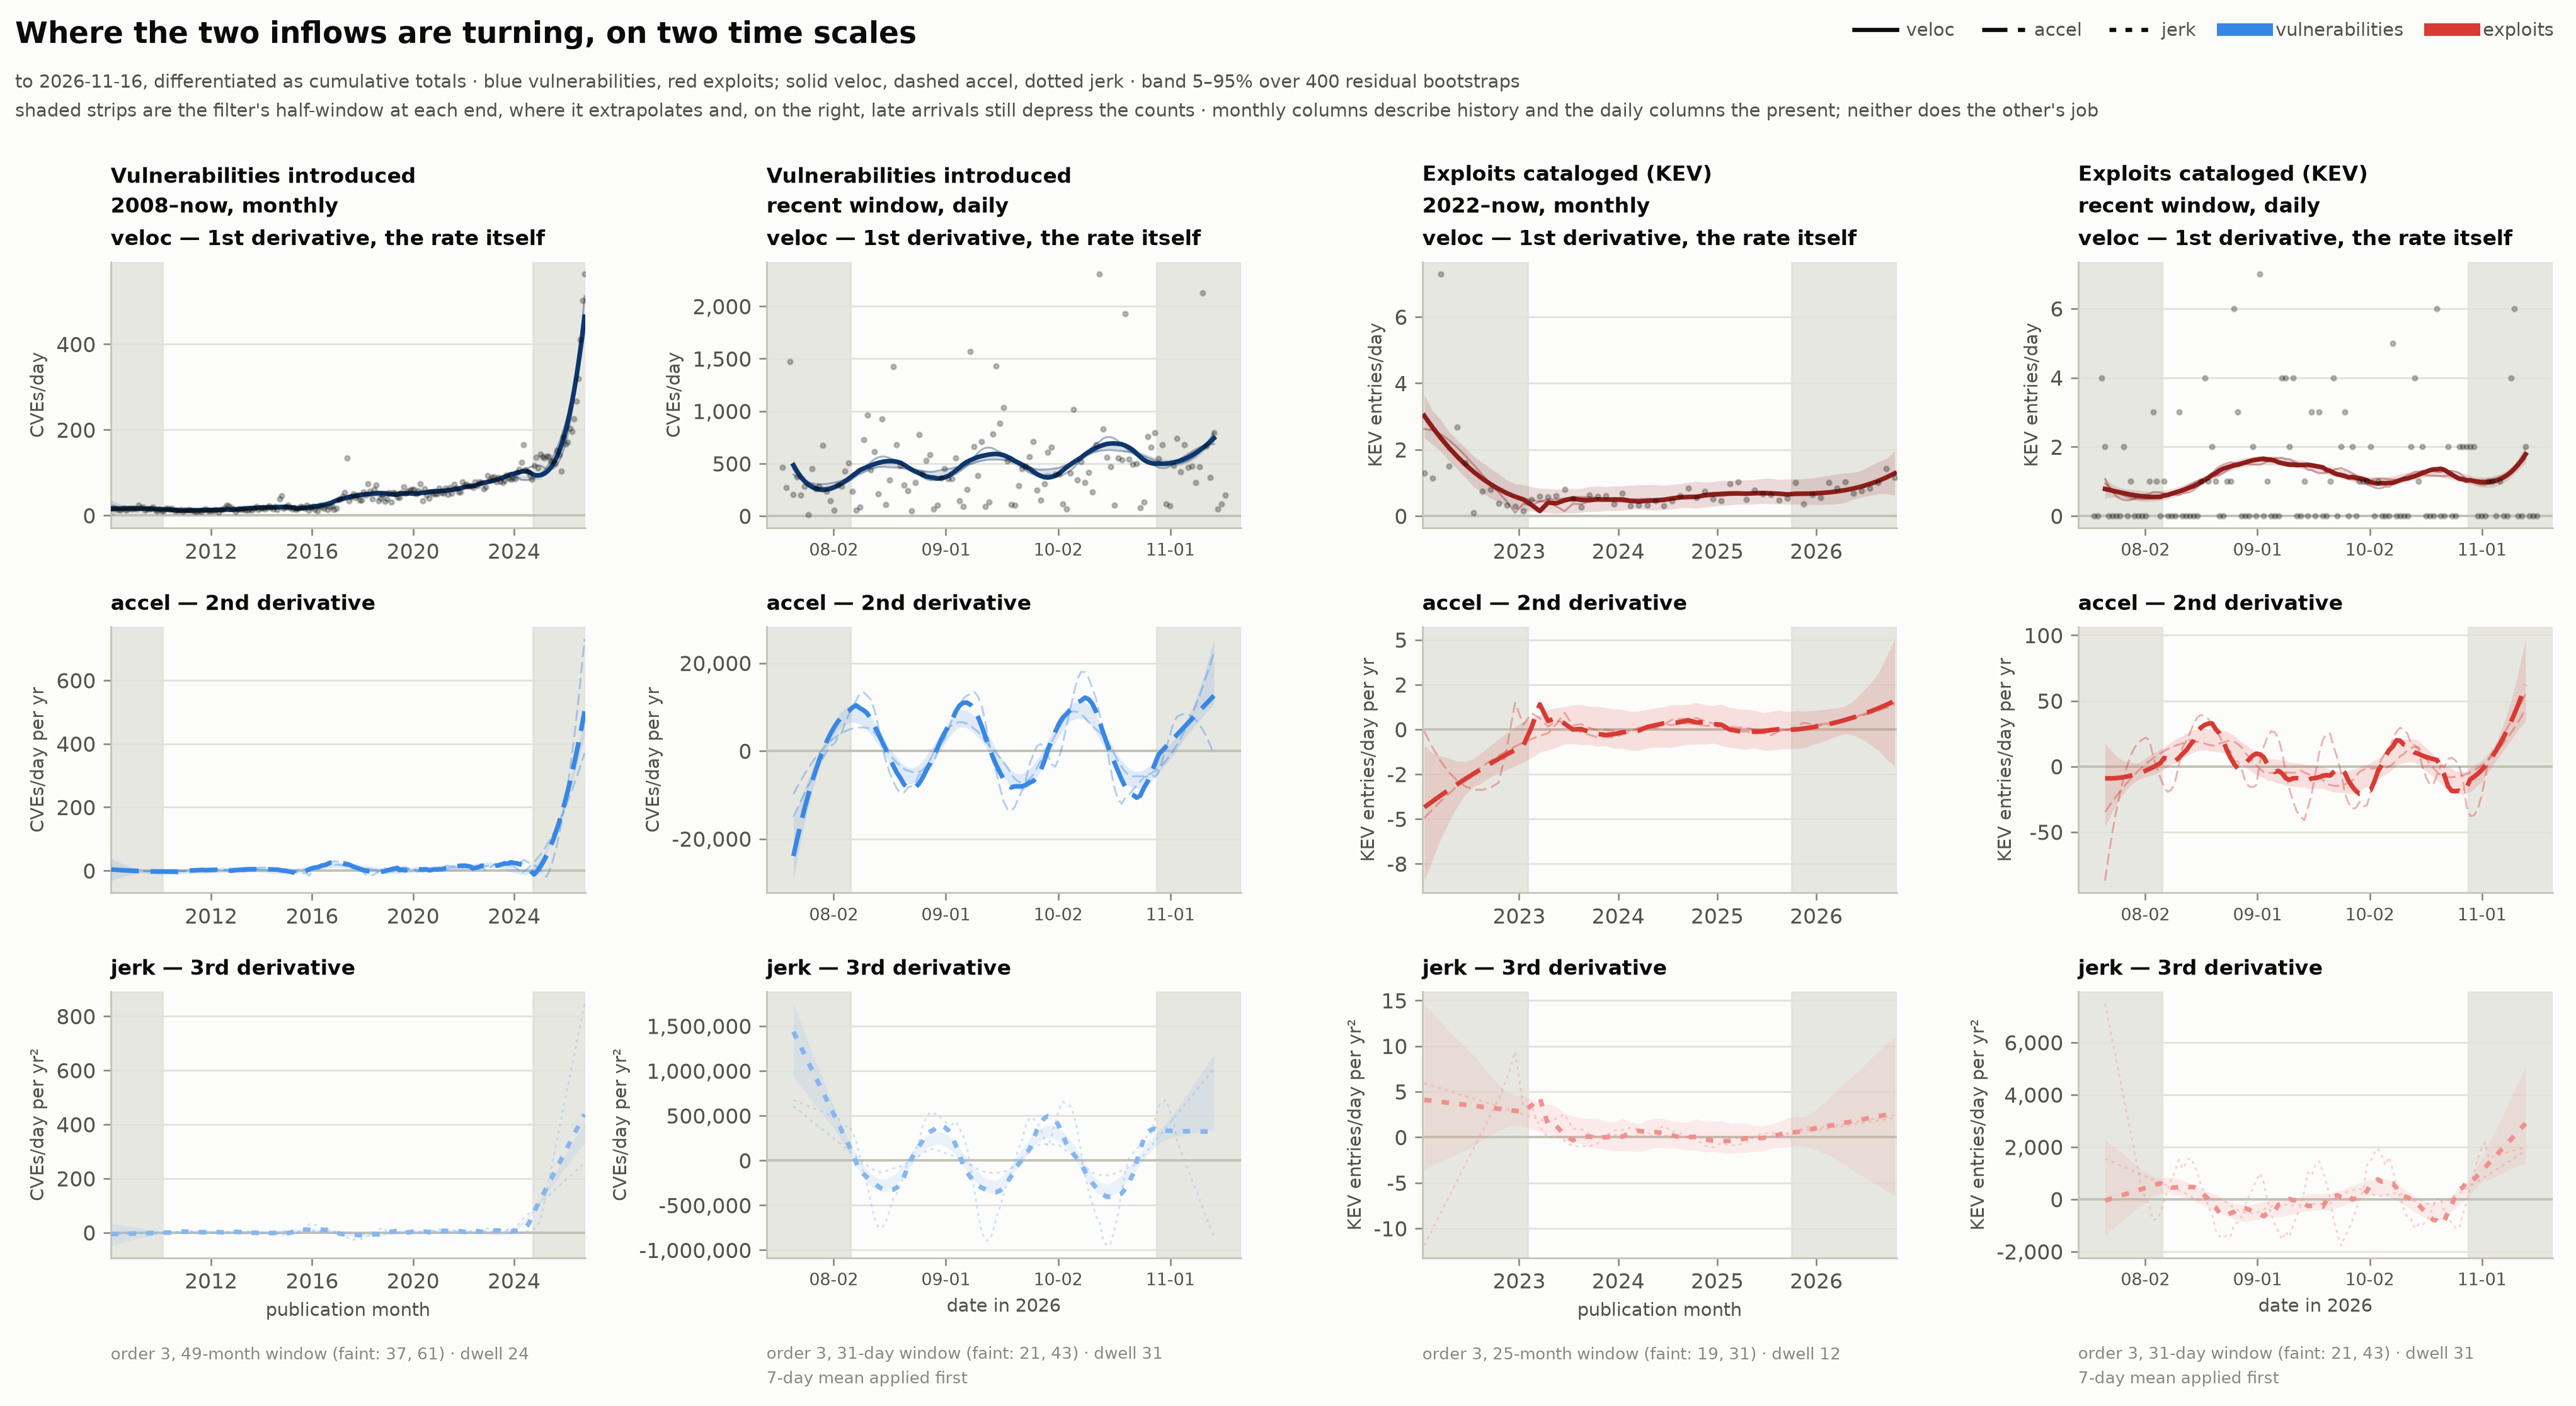

=== vulnerabilities introduced, monthly — 2008-01 to 2026-10, 226 points
    window 49, order 3, dwell 24; interior 2010-02 to 2024-10
    veloc  latest       464.15 CVEs/day                [     439.61,      469.54]  (edge, extrapolated)
    accel  latest       502.24 CVEs/day per yr         [     427.66,      489.18]  (edge, extrapolated)
    jerk   latest       437.70 CVEs/day per yr²        [     333.22,      407.18]  (edge, extrapolated)
    veloc  interior max      103.13 at 2024-06   min       11.42 at 2011-02
    accel  interior max       26.43 at 2023-11   min      -12.32 at 2015-05
    jerk   interior max       58.29 at 2024-09   min       -9.58 at 2017-11
    accel  negative for under 1 month (since 2024-09) — shorter than the 24-month dwell, not a settled sign
    jerk   positive for 61 months (since 2019-09)
    swings: none clear both the band and the dwell

=== vulnerabilities introduced, daily — 2026-07-22 to 2026-11-13, 115 points
    window 31, order 3, dwell 31; inte

In [13]:
FIGURE_NAME = "inflow_derivatives"   # inlined into VulnData.md at that marker
# Derivatives of the two inflows, on two grids. The quantity differentiated is the cumulative
# count, so the rows are veloc = dN/dt (the model's gamma), accel = d2N/dt2, jerk = d3N/dt3.
#
# Two grids because one cannot do both jobs. A filter wide enough to resolve a turning point
# in a nineteen-year monthly series extrapolates across its own half-window at each end, and
# for publications that half-window is two years - the two years over which the rate tripled.
# The monthly columns are about history and say nothing reliable about now; the daily columns
# are about now and say nothing about history.
#
# Order 3 is the lowest that admits a third derivative and, on a synthetic series with one
# known turning point, the highest that recovers it: at order 5 the fit is near-interpolating
# and the acceleration crosses zero 17 times instead of once. Windows are then set so that
# same test returns one crossing. Daily series get a centered 7-day mean first, which cancels
# a pure weekly cycle exactly; without it the publication weekday pattern leaks into every
# derivative.
import glob
from scipy.signal import savgol_filter

POLYORDER, N_BOOT, YEAR_D = 3, 400, 365.25
TREND_RNG = np.random.default_rng(20260920)
D_BLUE, D_RED = ["#0d366b", "#3987e5", "#86b6ef"], ["#8c1d1a", "#d93a34", "#f0908c"]
D_DASH = ["-", (0, (6, 2.5)), (0, (1.6, 2.2))]
D_ROW = ["veloc", "accel", "jerk"]
D_TITLE = ["veloc — 1st derivative, the rate itself", "accel — 2nd derivative",
           "jerk — 3rd derivative"]


def _newest(pattern):
    paths = sorted(glob.glob(f"data/{pattern}"))
    if not paths:
        raise SystemExit(f"no data/{pattern} — run VulnData.ipynb first")
    return json.loads(Path(paths[-1]).read_text())


def _decimal_year(d):
    return d.year + (d - dt.date(d.year, 1, 1)).days / (366 if d.year % 4 == 0 else 365)


def _monthly(rows, key, start=None):
    keep = [r for r in rows if r["complete"] and (start is None or r["month"] >= start)]
    t = np.array([int(r["month"][:4]) + (int(r["month"][5:7]) - 0.5) / 12 for r in keep])
    return t, np.array([r[key] / r["days"] for r in keep], float), [r["month"] for r in keep]


def _daily(rows, key):
    t = np.array([_decimal_year(dt.date.fromisoformat(r["date"])) for r in rows])
    y = np.array([r[key] for r in rows], float)
    sm = np.convolve(y, np.ones(7) / 7, mode="valid")        # drops 3 points at each end
    return t[3:-3], sm, [r["date"] for r in rows][3:-3], (t, y)


def _derivs(y, window, delta):
    return [savgol_filter(y, window, POLYORDER, deriv=k, delta=delta) for k in range(3)]


def _band(y, window, delta):
    fit = savgol_filter(y, window, POLYORDER, delta=delta)
    resid, draws = y - fit, [[] for _ in range(3)]
    for _ in range(N_BOOT):
        rep = fit + TREND_RNG.choice(resid, size=resid.size, replace=True)
        for k, d in enumerate(_derivs(rep, window, delta)):
            draws[k].append(d)
    return [(np.percentile(np.array(d), 5, axis=0), np.percentile(np.array(d), 95, axis=0))
            for d in draws]


def _dwell_for(window, cadence):
    """Samples the new sign must hold for a sign change to count as a swing.

    The larger of half the filter window and one release cadence; the two floors bind on
    different grids.

    Half the window is the scale on which the smoothed series stops being self-correlated:
    two Savitzky-Golay outputs less than one window apart are built from overlapping input,
    so a curve grazing zero throws several crossings inside that span however clean the
    signal is. At half a window each side of a crossing rests on largely separate days.

    The cadence floor exists because vendor releases are periodic, and a periodic component
    crosses zero twice per period forever. On the monthly grid the cadence is 12 months and
    the window floor already dominates (49 // 2 = 24). On the daily grid it is the ~31-day
    Patch Tuesday cycle and it is the binding one: at half of a 31-day window the publication
    series returned four "swings" in six weeks, alternating on almost exactly a monthly beat.
    The 7-day mean removes the weekly cycle; nothing removes the monthly one, so the dwell
    has to outlast it.

    It is also a high-pass cutoff on swing duration - a reversal that reverts inside the
    dwell is discarded - so it cannot be raised freely. On the daily grid it leaves little
    detectable inside a 115-day window, which is the correct answer rather than a failure:
    a sign change that does not outlast the release cadence cannot be told apart from it.
    """
    return max(6, window // 2, cadence)


def _crossings(t, mid, band, interior, dwell):
    lo, hi = band
    out = []
    for i in range(len(mid) - 1):
        if mid[i] == 0 or np.sign(mid[i]) == np.sign(mid[i + 1]):
            continue
        if not (interior[0] <= t[i] and t[i + 1] <= interior[1]):
            continue
        held_b = np.all(np.sign(mid[max(0, i - dwell):i + 1]) == np.sign(mid[i]))
        held_a = np.all(np.sign(mid[i + 1:i + 1 + dwell]) == np.sign(mid[i + 1]))
        near = slice(max(0, i - dwell), min(len(mid), i + 2 + dwell))
        clears = np.any(lo[near] > 0) and np.any(hi[near] < 0)
        frac = mid[i] / (mid[i] - mid[i + 1])
        out.append({"t": t[i] + frac * (t[i + 1] - t[i]),
                    "into": "positive" if mid[i + 1] > 0 else "negative",
                    "significant": bool(held_b and held_a and clears)})
    return out


def _run(t, mid, interior):
    """Sign at the last interior sample and how long it has held.

    The swing tests are conservative by design, so a null from them is common; this is well
    defined either way and is usually the honest statement of what the series is doing.
    """
    last = np.nonzero(t <= interior[1])[0][-1]
    sign, i = np.sign(mid[last]), last
    while i > 0 and np.sign(mid[i - 1]) == sign:
        i -= 1
    return {"sign": sign, "since": t[i], "held": t[last] - t[i], "from_start": i == 0}


def _lab(grid, t):
    y = int(np.floor(t))
    if grid == "monthly":
        m = int(round((t - y) * 12)) + 1
        return f"{y + 1}-{m - 12:02d}" if m > 12 else f"{y}-{max(1, m):02d}"
    doy = (t - y) * (366 if y % 4 == 0 else 365)
    return (dt.date(y, 1, 1) + dt.timedelta(days=int(round(doy)))).isoformat()


TREND = _newest("trend_series_*.json")
TREND_D = _newest("trend_daily_*.json")
TREND_AS_OF = dt.date.fromisoformat(TREND["as_of"])
D_SPECS = [
    dict(key="cve_m", grid="monthly", rows="monthly_cves", count="cves", start=None,
         window=49, alts=(37, 61), cadence=12, ramp=D_BLUE, unit="CVEs",
         name="vulnerabilities introduced, monthly",
         title="Vulnerabilities introduced\n2008–now, monthly"),
    dict(key="cve_d", grid="daily", count="cves", window=31, alts=(21, 43), cadence=31,
         ramp=D_BLUE, unit="CVEs", name="vulnerabilities introduced, daily",
         title="Vulnerabilities introduced\nrecent window, daily"),
    dict(key="kev_m", grid="monthly", rows="monthly_kev_added", count="kev", start="2022-01",
         window=25, alts=(19, 31), cadence=12, ramp=D_RED, unit="KEV entries",
         name="exploits cataloged, monthly",
         title="Exploits cataloged (KEV)\n2022–now, monthly"),
    dict(key="kev_d", grid="daily", count="kev", window=31, alts=(21, 43), cadence=31,
         ramp=D_RED, unit="KEV entries", name="exploits cataloged, daily",
         title="Exploits cataloged (KEV)\nrecent window, daily"),
]

fig, axes = plt.subplots(3, 4, figsize=(17.0, 9.6))
trend_report = {}
for col, spec in enumerate(D_SPECS):
    if spec["grid"] == "monthly":
        t, y, labels = _monthly(TREND[spec["rows"]], spec["count"], spec["start"])
        delta, raw = 1 / 12, None
    else:
        t, y, labels, raw = _daily(TREND_D["daily"], spec["count"])
        delta = 1 / YEAR_D
    w = spec["window"]
    d, bnd = _derivs(y, w, delta), _band(y, w, delta)
    alt = {a: _derivs(y, a, delta) for a in spec["alts"]}
    half = (w / 2) * (1 / 12 if spec["grid"] == "monthly" else 1 / YEAR_D)
    interior, dwell = (t[0] + half, t[-1] - half), _dwell_for(w, spec["cadence"])
    swings = [c for c in _crossings(t, d[1], bnd[1], interior, dwell) if c["significant"]]
    trend_report[spec["key"]] = dict(t=t, y=y, labels=labels, d=d, band=bnd, spec=spec,
                                     interior=interior, dwell=dwell, swings=swings)

    for row in range(3):
        ax, cc, ls = axes[row, col], spec["ramp"][row], D_DASH[row]
        ax.axhline(0, color=BASELINE, lw=1.2, zorder=2)
        ax.fill_between(t, *bnd[row], color=cc, alpha=0.15, lw=0, zorder=3)
        for a in spec["alts"]:
            ax.plot(t, alt[a][row], color=cc, ls=ls, lw=0.9, alpha=0.38, zorder=4)
        ax.plot(t, d[row], color=cc, ls=ls, lw=2.2, zorder=5)
        if row == 0:
            px, py = (raw if raw is not None else (t, y))
            ax.plot(px, py, ls="", marker="o", ms=2.2, color=INK, alpha=0.24, zorder=6)
        for a, b in ((t[0] - 0.02, interior[0]), (interior[1], t[-1] + 0.02)):
            ax.axvspan(a, b, color=GRID, alpha=0.75, zorder=1)
        for c in swings:
            ax.axvline(c["t"], color=INK, lw=1.0, ls=(0, (3, 3)), zorder=6)
        ax.set_xlim(t[0] - 0.02, t[-1] + 0.02)
        ax.set_axisbelow(True)
        ax.set_title(f"{spec['title']}\n{D_TITLE[row]}" if row == 0 else D_TITLE[row],
                     linespacing=1.55, fontsize=9.8)
        ax.set_ylabel([f"{spec['unit']}/day", f"{spec['unit']}/day per yr",
                       f"{spec['unit']}/day per yr²"][row], fontsize=8.8)
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(
            lambda v, _: f"{v:,.3g}" if abs(v) < 1 else f"{v:,.0f}"))
        if spec["grid"] == "monthly":
            ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(4 if col == 0 else 1))
            ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{int(v)}"))
        else:
            ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(1 / 12))
            ax.xaxis.set_major_formatter(
                mpl.ticker.FuncFormatter(lambda v, _, g=spec["grid"]: _lab(g, v)[5:]))
            ax.tick_params(axis="x", labelsize=8)
    for c in swings:
        axes[1, col].annotate(_lab(spec["grid"], c["t"]), xy=(c["t"], 1.0),
                              xycoords=("data", "axes fraction"), xytext=(3, -8),
                              textcoords="offset points", ha="left", va="top", fontsize=8,
                              color=INK, fontweight="bold", zorder=7)
    axes[2, col].set_xlabel("publication month" if spec["grid"] == "monthly"
                            else f"date in {TREND_AS_OF.year}", fontsize=8.8)
    axes[2, col].annotate(
        f"order {POLYORDER}, {w}-{'month' if spec['grid'] == 'monthly' else 'day'} window"
        f" (faint: {spec['alts'][0]}, {spec['alts'][1]}) · dwell {dwell}"
        + ("\n7-day mean applied first" if spec["grid"] == "daily" else ""),
        xy=(0.0, 0.0), xycoords="axes fraction", xytext=(0, -40), textcoords="offset points",
        ha="left", va="top", fontsize=7.8, color=MUTED, linespacing=1.5)

fig.text(0.004, 0.995, "Where the two inflows are turning, on two time scales", ha="left",
         va="top", fontsize=14, fontweight="bold", color=INK)
fig.legend([plt.Line2D([], [], color=INK, ls=D_DASH[i], lw=2.0) for i in range(3)]
           + [plt.Line2D([], [], color=D_BLUE[1], lw=6), plt.Line2D([], [], color=D_RED[1], lw=6)],
           D_ROW + ["vulnerabilities", "exploits"], loc="upper right",
           bbox_to_anchor=(0.998, 1.005), ncol=5, fontsize=8.6, handlelength=2.4,
           handletextpad=0.5, columnspacing=1.5, labelcolor=SECONDARY)
fig.text(0.004, 0.962,
         f"to {TREND_AS_OF}, differentiated as cumulative totals · blue vulnerabilities, red "
         f"exploits; solid veloc, dashed accel, dotted jerk · band 5–95% over {N_BOOT} "
         f"residual bootstraps\nshaded strips are the filter's half-window at each end, where "
         f"it extrapolates and, on the right, late arrivals still depress the counts · "
         f"monthly columns describe history and the daily columns the present; neither does "
         f"the other's job",
         ha="left", va="top", fontsize=8.6, color=SECONDARY, linespacing=1.6)
fig.tight_layout(rect=(0, 0.035, 1, 0.915))
plt.show()

for spec in D_SPECS:
    r = trend_report[spec["key"]]
    t, d, bnd, lab, g = r["t"], r["d"], r["band"], r["labels"], spec["grid"]
    inside = (t >= r["interior"][0]) & (t <= r["interior"][1])
    unit, samp = spec["unit"], ("month" if g == "monthly" else "day")
    print(f"=== {spec['name']} — {lab[0]} to {lab[-1]}, {len(lab)} points")
    print(f"    window {spec['window']}, order {POLYORDER}, dwell {r['dwell']}; interior "
          f"{_lab(g, r['interior'][0])} to {_lab(g, r['interior'][1])}")
    for k in range(3):
        u = [f"{unit}/day", f"{unit}/day per yr", f"{unit}/day per yr²"][k]
        print(f"    {D_ROW[k]:<6} latest {d[k][-1]:>12,.2f} {u:<24}"
              f"[{bnd[k][0][-1]:>11,.2f}, {bnd[k][1][-1]:>11,.2f}]"
              + ("" if inside[-1] else "  (edge, extrapolated)"))
    li = [l for l, s in zip(lab, inside) if s]
    for k in range(3):
        di = d[k][inside]
        print(f"    {D_ROW[k]:<6} interior max {di.max():>11,.2f} at {li[int(di.argmax())]}"
              f"   min {di.min():>11,.2f} at {li[int(di.argmin())]}")
    for k in (1, 2):
        run = _run(t, d[k], r["interior"])
        n = int(round(run["held"] * (12 if g == "monthly" else YEAR_D)))
        word = "positive" if run["sign"] > 0 else "negative" if run["sign"] < 0 else "zero"
        body = f"under 1 {samp}" if n < 1 else f"{n} {samp}{'s' if n != 1 else ''}"
        tail = (f" — shorter than the {r['dwell']}-{samp} dwell, not a settled sign"
                if n < r["dwell"] else "")
        since = "the start of the series" if run["from_start"] else _lab(g, run["since"])
        print(f"    {D_ROW[k]:<6} {word} for {body} (since {since}){tail}")
    print("    swings: " + (", ".join(f"{_lab(g, c['t'])}→{c['into']}" for c in r["swings"])
                            or "none clear both the band and the dwell"))
    print()

## 9. Stratification by product type

The four figures of the data page's last section. `cve_strata.py` gives every CVE a `ptype` (operating
system, productivity server, client / user app, edge device, other) and its `report` writes the tables to
`data/cve_ptype_<snapshot>.json`, which is all these cells read: they draw and compute nothing. To refresh,
run `python3 cve_strata.py update` and `python3 cve_strata.py report --as-of <snapshot>` first. One color per
type, the same in every figure.

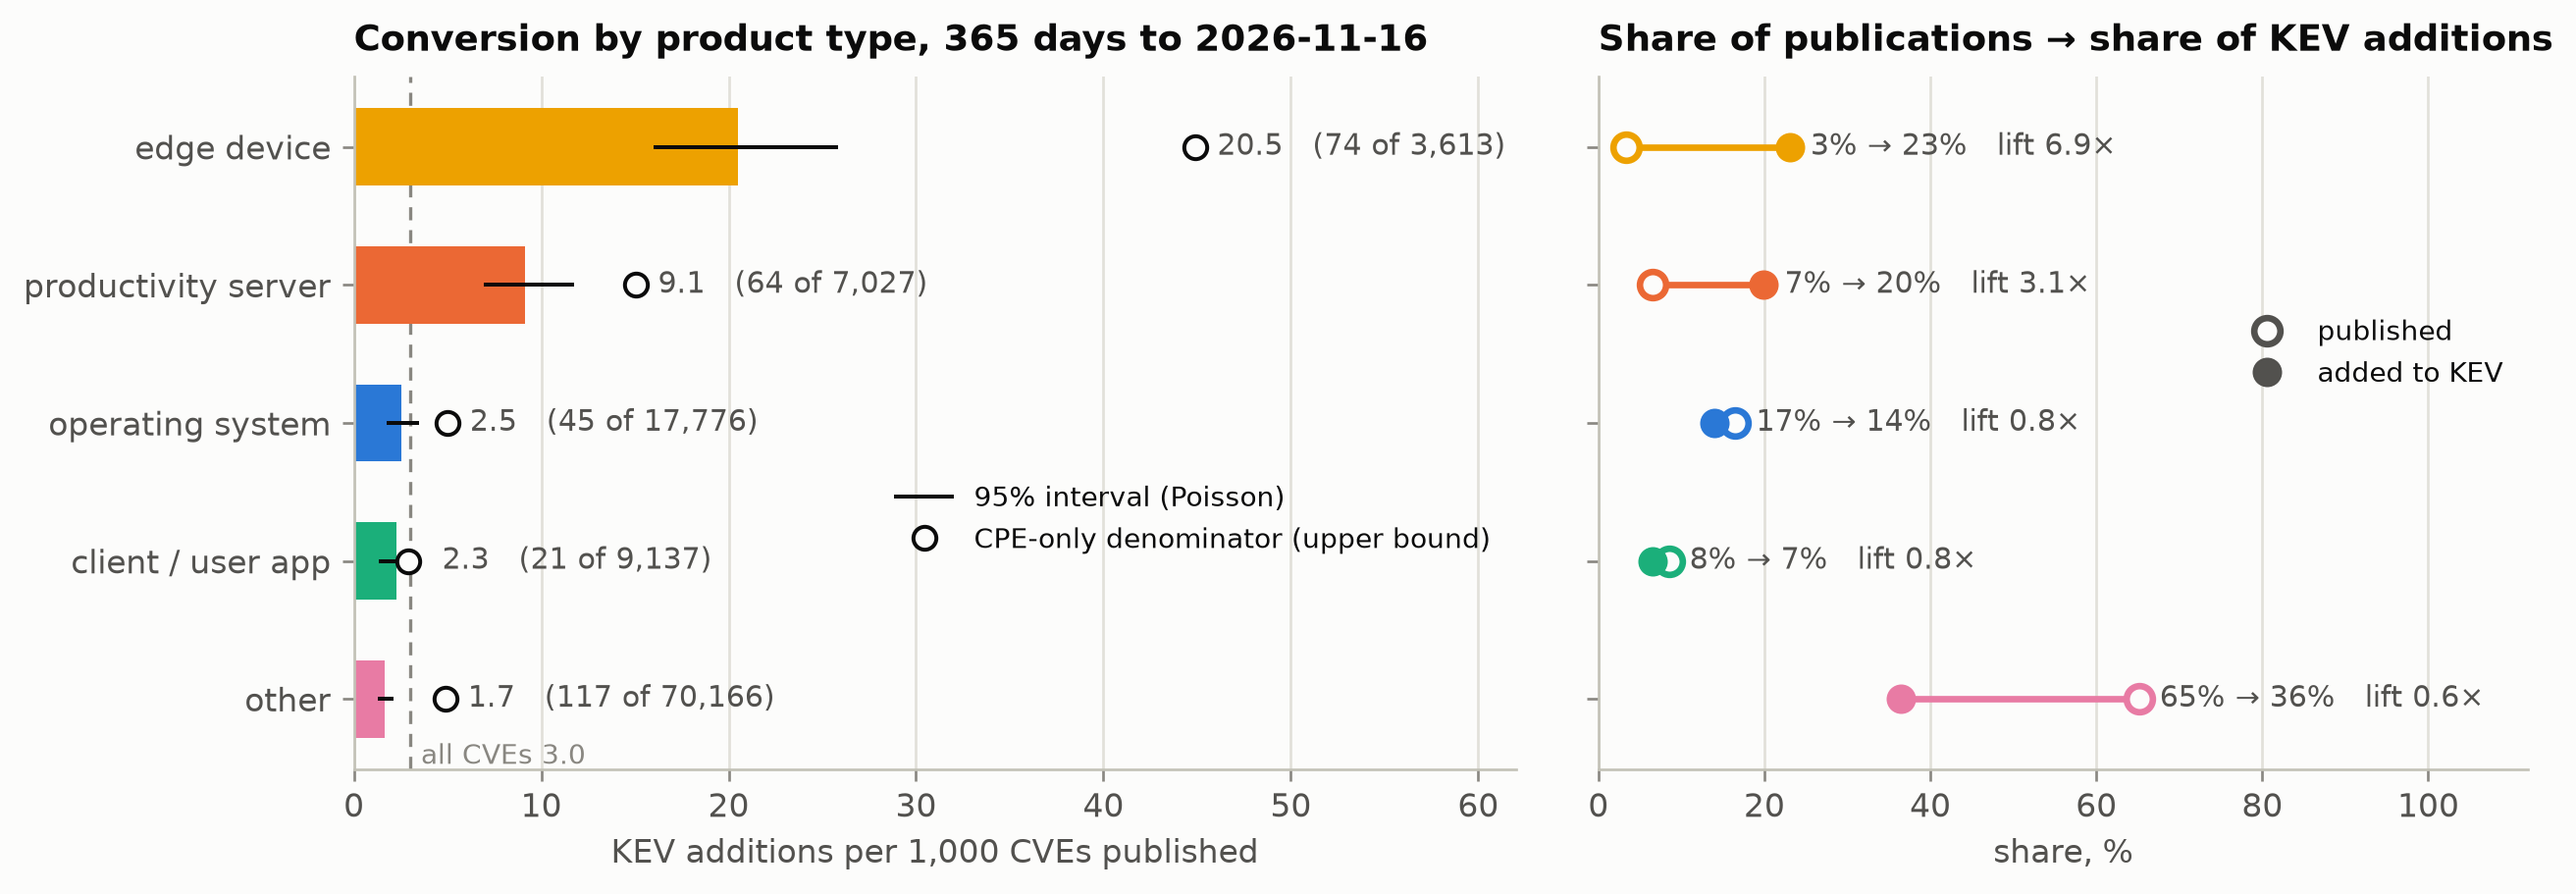

In [3]:
FIGURE_NAME = "ptype_conversion"   # inlined into VulnData.md at that marker
# Conversion by product type: KEV additions per 1,000 CVEs published in the window. The bar uses
# the imputed denominator and the open marker the CPE-only one, which is an upper bound; the
# whisker is the exact Poisson 95% interval on the count of additions.
P = json.loads((DATA / f"cve_ptype_{TAG}.json").read_text())
PT = ["os", "prodserver", "client", "edge", "other"]          # fixed order, fixed colors
PT_COLOR = dict(zip(PT, SERIES))
PT_NAME = {t: P["types"][t]["name"] for t in PT}
T = P["types"]
overall = 1000 * P["kev_added"] / P["published"]
order = sorted(PT, key=lambda t: T[t]["per_1000"])

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.25, 1]})
y = np.arange(len(order))
ax.barh(y, [T[t]["per_1000"] for t in order], height=0.56, color=[PT_COLOR[t] for t in order],
        zorder=2)
for i, t in enumerate(order):
    c = T[t]
    ax.plot([c["per_1000_lo"], c["per_1000_hi"]], [i, i], color=INK, lw=1.2, zorder=3)
    ax.plot(c["per_1000_cpe_only"], i, "o", ms=7, mfc=SURFACE, mec=INK, mew=1.2, zorder=4)
    ax.text(max(c["per_1000_hi"], c["per_1000_cpe_only"]) + 1.2, i,
            f"{c['per_1000']:.1f}   ({c['kev_added']} of {c['published_imputed']:,.0f})",
            va="center", fontsize=9, color=SECONDARY)
ax.axvline(overall, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
ax.text(overall + 0.6, -0.47, f"all CVEs {overall:.1f}", fontsize=8.5, color=MUTED)
ax.set_yticks(y, [PT_NAME[t] for t in order])
ax.set_xlim(0, 62)
ax.set_xlabel("KEV additions per 1,000 CVEs published")
ax.set_title(f"Conversion by product type, {P['window_days']} days to {P['as_of']}")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.plot([], [], color=INK, lw=1.2, label="95% interval (Poisson)")
ax.plot([], [], "o", ms=7, mfc=SURFACE, mec=INK, mew=1.2, ls="", label="CPE-only denominator (upper bound)")
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.36), fontsize=8.5)

for i, t in enumerate(order):
    a, b = 100 * T[t]["share_published"], 100 * T[t]["share_kev"]
    bx.plot([a, b], [i, i], color=PT_COLOR[t], lw=2, zorder=2)
    bx.plot(a, i, "o", ms=8, mfc=SURFACE, mec=PT_COLOR[t], mew=2, zorder=3)
    bx.plot(b, i, "o", ms=8, color=PT_COLOR[t], zorder=3)
    bx.text(max(a, b) + 2.5, i, f"{a:.0f}% → {b:.0f}%   lift {T[t]['lift']:.1f}×", va="center",
            fontsize=9, color=SECONDARY)
bx.set_yticks(y, [""] * len(order)); bx.set_ylim(ax.get_ylim())
bx.set_xlim(0, 112); bx.set_xticks(range(0, 101, 20)); bx.set_xlabel("share, %")
bx.set_title("Share of publications → share of KEV additions")
bx.grid(axis="y", visible=False); bx.grid(axis="x", visible=True)
bx.plot([], [], "o", ms=8, mfc=SURFACE, mec=SECONDARY, mew=2, ls="", label="published")
bx.plot([], [], "o", ms=8, color=SECONDARY, ls="", label="added to KEV")
bx.legend(loc="center right", bbox_to_anchor=(1.0, 0.6), fontsize=8.5)
fig.tight_layout()
plt.show()

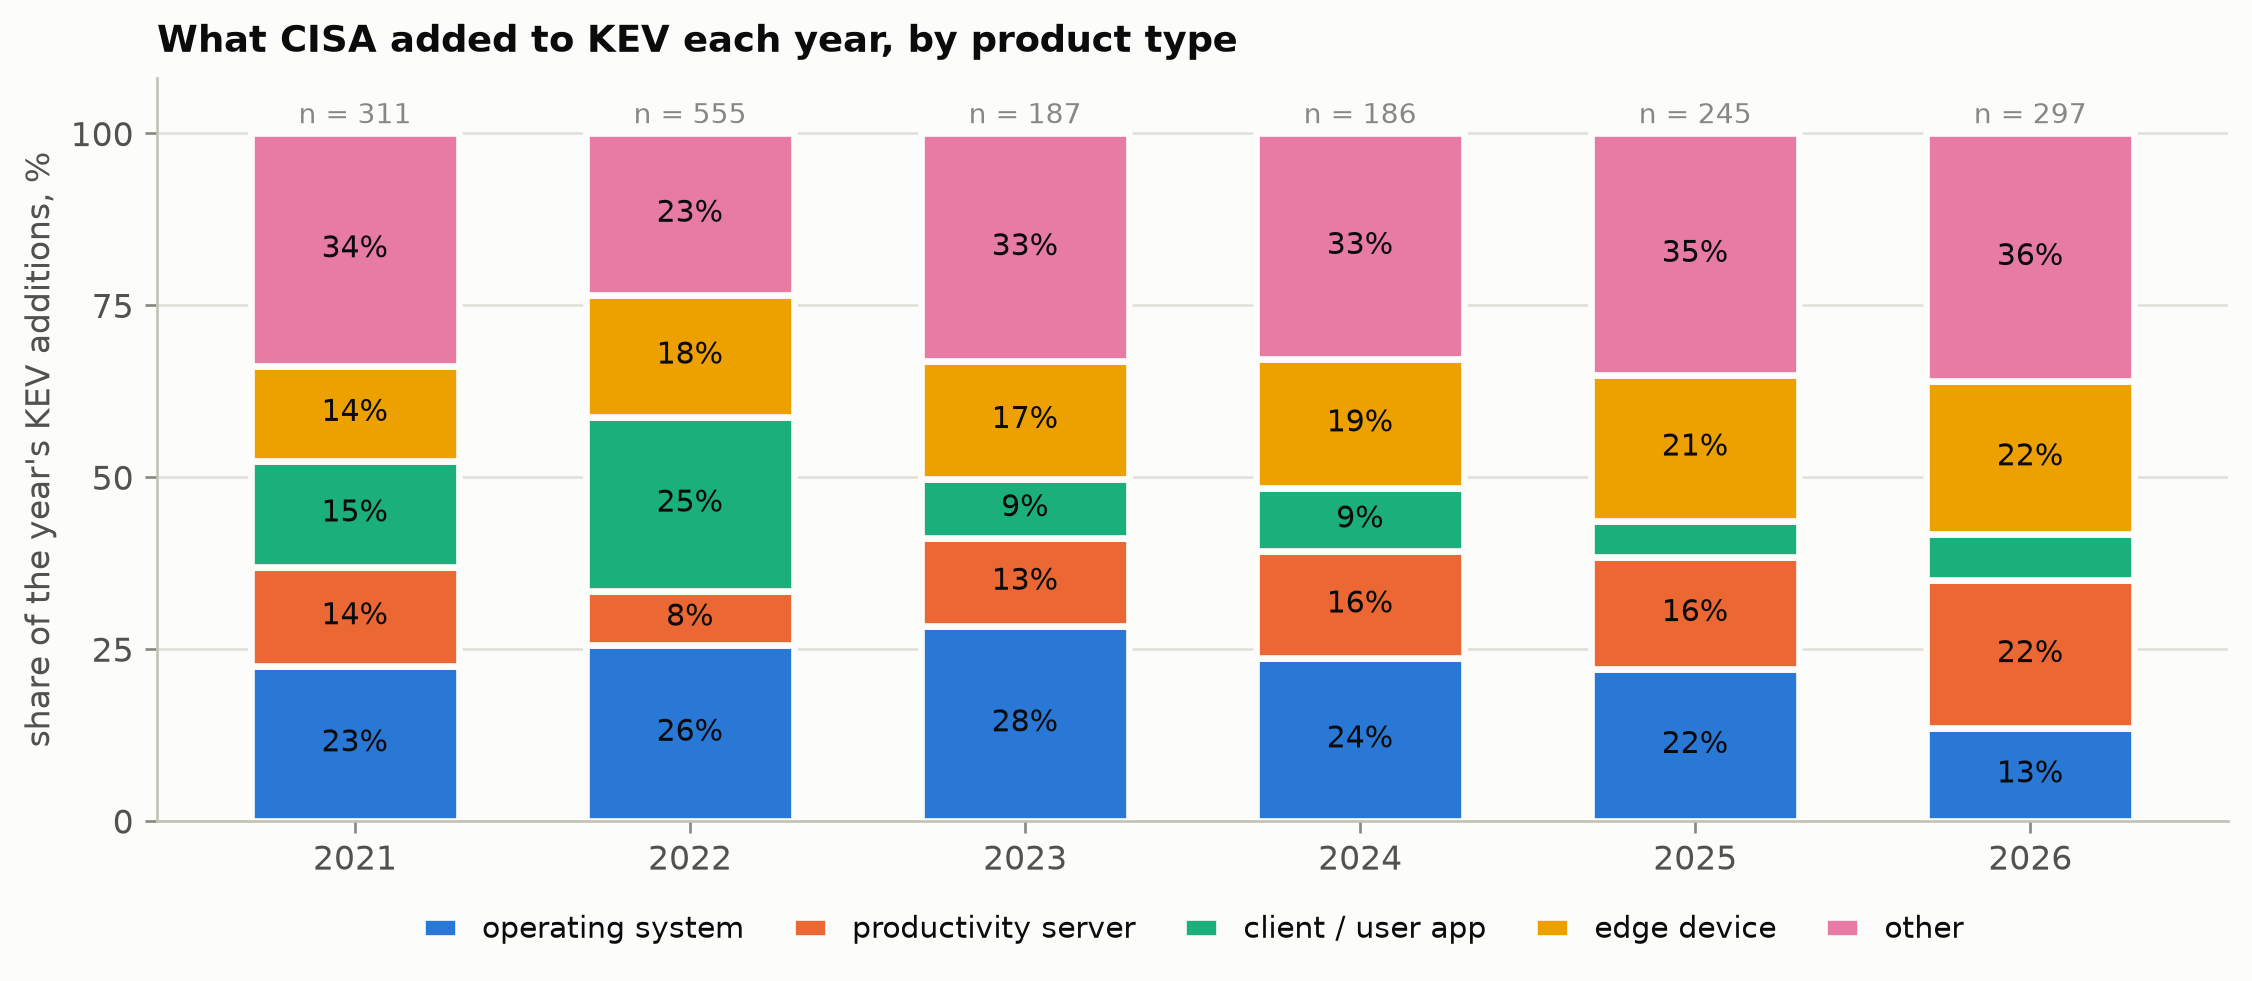

In [4]:
FIGURE_NAME = "ptype_composition"   # inlined into VulnData.md at that marker
# Composition of KEV additions by year added, whole catalog. There are no publication counts by
# type before the table's floor, so this shows shares only: which of the window's shares are
# habits of the catalog and which belong to one year.
Y = P["kev_by_year_added"]
years = list(Y)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
bottom = np.zeros(len(years))
for t in PT:
    share = np.array([100 * Y[yr][t] / sum(Y[yr].values()) for yr in years])
    ax.bar(years, share, bottom=bottom, width=0.62, color=PT_COLOR[t], edgecolor=SURFACE,
           linewidth=2, label=PT_NAME[t], zorder=2)
    for x, (s, b) in enumerate(zip(share, bottom)):
        if s >= 7:
            ax.text(x, b + s / 2, f"{s:.0f}%", ha="center", va="center", fontsize=9, color=INK)
    bottom += share
for x, yr in enumerate(years):
    ax.text(x, 101.5, f"n = {sum(Y[yr].values())}", ha="center", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 108); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel("share of the year's KEV additions, %")
ax.set_title("What CISA added to KEV each year, by product type")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.09), fontsize=9,
          handlelength=1.2, columnspacing=1.6)
fig.tight_layout()
plt.show()

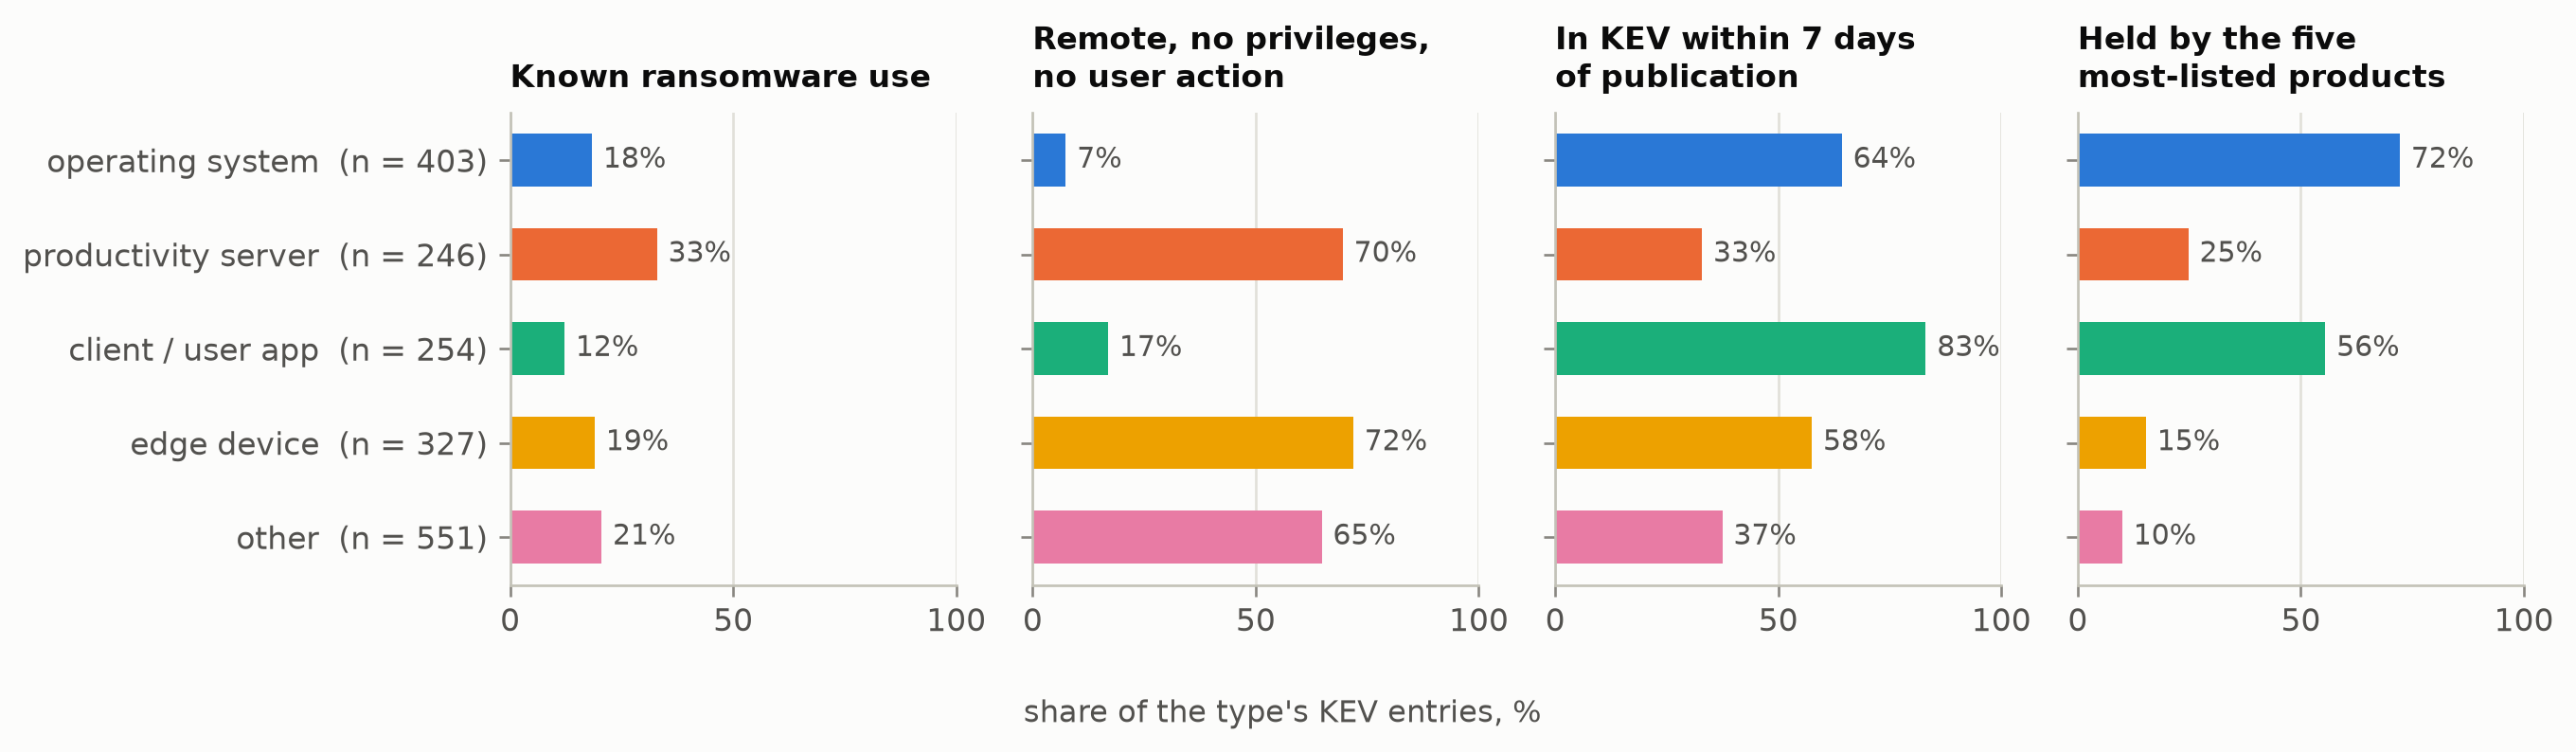

In [5]:
FIGURE_NAME = "ptype_profile"   # inlined into VulnData.md at that marker
# What each type's KEV entries look like, whole catalog: four shares on a common 0-100 scale.
R = P["kev_profile"]
PANELS = [("ransomware", "Known ransomware use"),
          ("remote_unauthenticated", "Remote, no privileges,\nno user action"),
          ("within_7_days", "In KEV within 7 days\nof publication"),
          ("top5_share", "Held by the five\nmost-listed products")]
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.3), sharey=True)
y = np.arange(len(PT))[::-1]
for ax, (key, title) in zip(axes, PANELS):
    vals = [100 * R[t][key] for t in PT]
    ax.barh(y, vals, height=0.56, color=[PT_COLOR[t] for t in PT], zorder=2)
    for yi, v in zip(y, vals):
        ax.text(v + 2.5, yi, f"{v:.0f}%", va="center", fontsize=9, color=SECONDARY)
    ax.set_xlim(0, 100); ax.set_xticks([0, 50, 100])
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
axes[0].set_yticks(y, [f"{PT_NAME[t]}  (n = {R[t]['entries']})" for t in PT])
fig.supxlabel("share of the type's KEV entries, %", fontsize=9.5, color=SECONDARY)
fig.tight_layout()
plt.show()

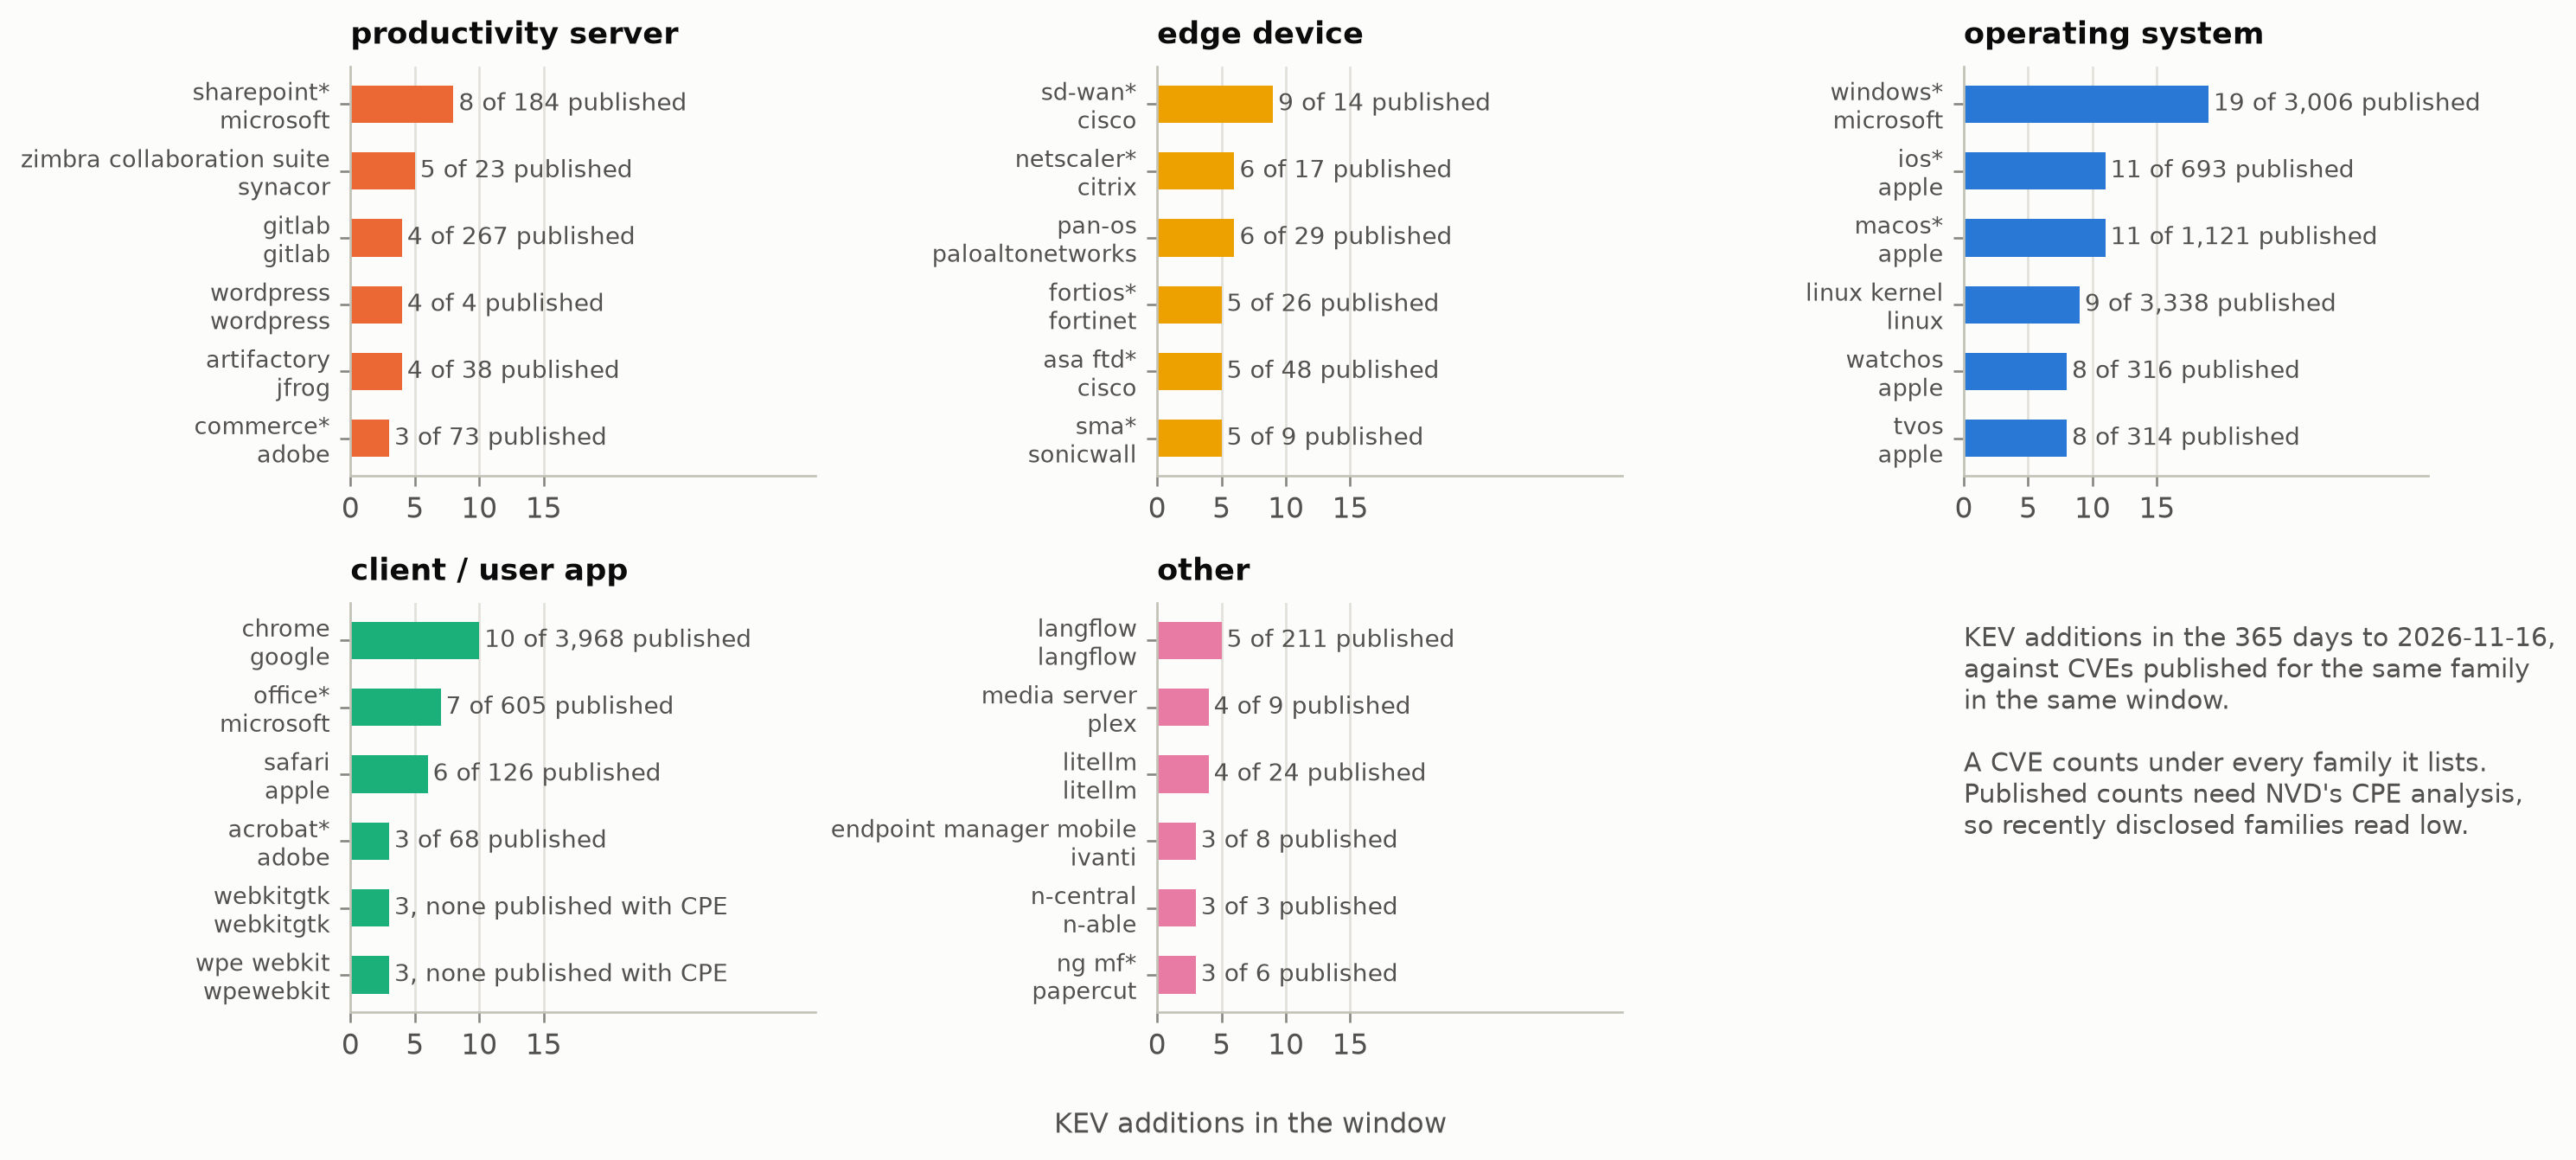

In [6]:
FIGURE_NAME = "ptype_top_families"   # inlined into VulnData.md at that marker
# The families with the most KEV additions in the window, per type. Bar length is the count of
# additions; the label gives the denominator, because a rate on a handful of published CVEs
# is not a rate. A trailing * marks releases grouped into one family.
F = P["top_families"]
SHOW = 6
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
xmax = max(f["kev_added"] for t in PT for f in F[t][:SHOW])
for ax, t in zip(axes.flat, ["prodserver", "edge", "os", "client", "other"]):
    fams = F[t][:SHOW]
    y = np.arange(len(fams))[::-1]
    ax.barh(y, [f["kev_added"] for f in fams], height=0.56, color=PT_COLOR[t], zorder=2)
    for yi, f in zip(y, fams):
        ax.text(f["kev_added"] + 0.4, yi, (f"{f['kev_added']} of {f['published']:,} published" if f["published"]
                                             else f"{f['kev_added']}, none published with CPE"),
                va="center", fontsize=8.5, color=SECONDARY)
    ax.set_yticks(y, [f["family"].split(":", 1)[1].replace("_", " ")[:26] + "\n" +
                      f["family"].split(":")[0] for f in fams], fontsize=8)
    ax.set_xlim(0, xmax * 1.9); ax.set_xticks(range(0, xmax + 1, 5))
    ax.set_title(PT_NAME[t], fontsize=10.5)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
note = axes.flat[5]; note.axis("off")
note.text(0, 0.95, f"KEV additions in the {P['window_days']} days to {P['as_of']},\n"
          "against CVEs published for the same family\nin the same window.\n\n"
          "A CVE counts under every family it lists.\nPublished counts need NVD's CPE analysis,\n"
          "so recently disclosed families read low.", va="top", fontsize=9, color=SECONDARY,
          transform=note.transAxes)
fig.supxlabel("KEV additions in the window", fontsize=9.5, color=SECONDARY)
fig.tight_layout()
plt.show()